<a href="https://colab.research.google.com/github/Vyachick228/pattern-recognition-practice/blob/main/classification-mini-project/notebooks/PR04_Shapovalov_Vladyslav.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Практичні роботи 4

## Мініпроєкт «Порівняння класичних моделей класифікації»

**Дисципліна:** Розпізнавання образів та класичне машинне навчання

**Студент:** Шаповалов Владислав

**Група:** ІН-32/2

**Дата виконання:** 05.11.2026

### Мета роботи

Навчитися будувати Pipeline машинного навчання, застосовувати класичні алгоритми класифікації, налаштовувати їхні гіперпараметри та порівнювати моделі за допомогою крос-валідації.

# Практична робота 4. Підготовка даних і логістична регресія
Спочатку відокремлюємо тестові дані. Усі перетворення виконуються всередині Pipeline, щоб не допустити витоку інформації.

In [9]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from google.colab import drive
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project')
DATA = ROOT / 'data' / 'heart_disease.csv'
assert DATA.exists(), f'Файл не знайдено: {DATA}'
for folder in ['reports', 'models']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA, na_values=['?'])
num = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
print('Розмір:', data.shape, '\nПропуски:', data.isna().sum().sum())
print('Типи:', data.dtypes.to_dict(), '\nКласи:', data.target.value_counts().to_dict())
display(data.head())
assert list(data.columns) == num[:1] + ['sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
assert set(data.target.unique()) == {0, 1}
X, y = data.drop(columns='target'), data.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape, '(test ще не оцінюємо)')

def pipe(model, scale=True, drop=None):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale: num_steps.append(('scaler', StandardScaler()))
    pre = ColumnTransformer([
        ('num', Pipeline(num_steps), num),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop=drop))]), cat)
    ])
    return Pipeline([('preprocessor', pre), ('classifier', model)])

def evaluate(name, model, params='-'):
    with warnings.catch_warnings(record=True) as warns:
        warnings.simplefilter('always')
        r = cross_validate(model, X_train, y_train, cv=cv,
                           scoring={'f1':'f1', 'auc':'roc_auc', 'recall':'recall'}, error_score='raise')
    critical = [str(w.message) for w in warns if any(term in str(w.message).lower()
                for term in ['covariance', 'rank', 'collinear', 'singular'])]
    return dict(model=name, params=str(params), cv_f1=r['test_f1'].mean(),
                cv_f1_std=r['test_f1'].std(), cv_auc=r['test_auc'].mean(),
                cv_recall=r['test_recall'].mean(), seconds=r['fit_time'].mean(),
                warning_count=len(warns), critical_warning_count=len(critical))

def best_row(df):
    return df.sort_values(['cv_f1', 'cv_recall', 'cv_f1_std', 'model'],
                          ascending=[False, False, True, True]).iloc[0]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Розмір: (303, 14) 
Пропуски: 6
Типи: {'age': dtype('int64'), 'sex': dtype('int64'), 'cp': dtype('int64'), 'trestbps': dtype('int64'), 'chol': dtype('int64'), 'fbs': dtype('int64'), 'restecg': dtype('int64'), 'thalach': dtype('int64'), 'exang': dtype('int64'), 'oldpeak': dtype('float64'), 'slope': dtype('int64'), 'ca': dtype('float64'), 'thal': dtype('float64'), 'target': dtype('int64')} 
Класи: {0: 164, 1: 139}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Train: (242, 13) Test: (61, 13) (test ще не оцінюємо)


,model,params,cv_f1,cv_f1_std,cv_auc,cv_recall,seconds,warning_count,critical_warning_count,n_iter
0,Без масштабування,-,0.825,0.007,0.902,0.783,0.018,0,0,13
1,Масштабування,-,0.825,0.007,0.902,0.783,0.018,0,0,6


,penalty,C,cv_f1,cv_f1_std,cv_auc
0,l1,0.01,0.000,0.000,0.500
1,l1,0.10,0.793,0.031,0.884
2,l1,1.00,0.812,0.017,0.907
3,l1,10.00,0.832,0.011,0.902
4,l1,100.00,0.836,0.013,0.897
5,l2,0.01,0.766,0.017,0.889
6,l2,0.10,0.814,0.030,0.902
7,l2,1.00,0.825,0.007,0.902
8,l2,10.00,0.836,0.013,0.900
9,l2,100.00,0.836,0.013,0.898


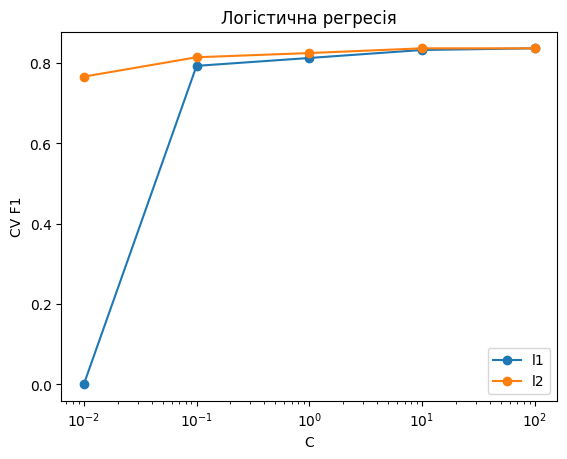

Найкращі параметри: {'penalty': 'l1', 'C': 100.0} CV F1: 0.836


,coefficient
cat__ca_0.0,-2.210591
cat__thal_7.0,1.482574
cat__restecg_1.0,-1.453688
cat__sex_0.0,-1.422631
cat__cp_4.0,1.309348


Висновок ПР4: масштабування впливає на збіжність, а C та L1/L2 — на складність моделі.


In [10]:
# Вплив масштабування: дві моделі, однакові CV-фолди.
scale_rows = []
for scale in [False, True]:
    model = pipe(LogisticRegression(max_iter=2000, solver='liblinear', random_state=42), scale)
    rec = evaluate('Масштабування' if scale else 'Без масштабування', model)
    model.fit(X_train, y_train)
    rec['n_iter'] = model.named_steps['classifier'].n_iter_[0]
    scale_rows.append(rec)
display(pd.DataFrame(scale_rows).round(3))

# L1/L2 та C. Вибір лише за CV F1.
log_rows = []
for penalty in ['l1', 'l2']:
    for C in [0.01, 0.1, 1, 10, 100]:
        model = pipe(LogisticRegression(penalty=penalty, C=C, solver='liblinear', max_iter=2000, random_state=42))
        log_rows.append(evaluate('LogisticRegression', model, {'penalty':penalty, 'C':C}) |
                        {'penalty':penalty, 'C':C})
log_table = pd.DataFrame(log_rows)
display(log_table[['penalty', 'C', 'cv_f1', 'cv_f1_std', 'cv_auc']].round(3))
for penalty, g in log_table.groupby('penalty'):
    plt.plot(g.C, g.cv_f1, marker='o', label=penalty)
plt.xscale('log'); plt.xlabel('C'); plt.ylabel('CV F1'); plt.title('Логістична регресія'); plt.legend(); plt.show()
choice = best_row(log_table)
log_params = {'penalty':choice.penalty, 'C':float(choice.C)}
log_model = pipe(LogisticRegression(**log_params, solver='liblinear', max_iter=2000, random_state=42))
log_model.fit(X_train, y_train)
coef = pd.Series(log_model.named_steps['classifier'].coef_[0],
                 index=log_model.named_steps['preprocessor'].get_feature_names_out())
print('Найкращі параметри:', log_params, 'CV F1:', round(choice.cv_f1, 3))
display(coef.loc[coef.abs().sort_values(ascending=False).head().index].to_frame('coefficient'))
print('Висновок ПР4: масштабування впливає на збіжність, а C та L1/L2 — на складність моделі.')

# Практична робота 5. k-NN і ймовірнісні моделі
Порівнюємо k-NN, GaussianNB, LDA і QDA лише на навчальній вибірці.

,model,params,cv_f1,cv_f1_std,cv_auc,cv_recall,seconds,warning_count,critical_warning_count
0,kNN без масштабу,-,0.512,0.013,0.642,0.487,0.058,0,0
1,kNN з масштабом,-,0.799,0.043,0.871,0.783,0.074,0,0


,k,cv_f1,cv_f1_std
0,3,0.804,0.027
1,5,0.799,0.043
2,7,0.794,0.018
3,9,0.787,0.029
4,11,0.779,0.027
5,15,0.765,0.025


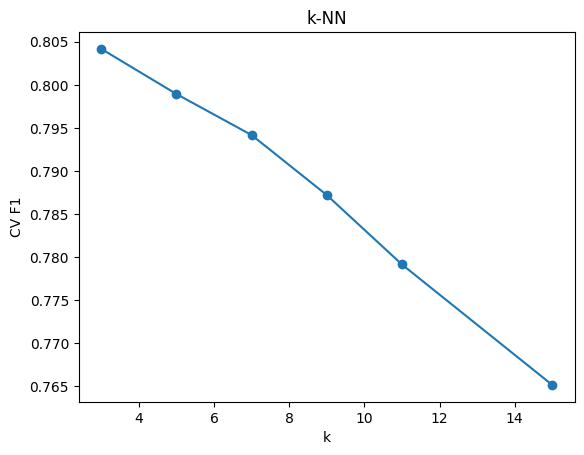

,metric,cv_f1,cv_f1_std,cv_auc
0,euclidean,0.804,0.027,0.871
1,manhattan,0.818,0.030,0.877


Найкращий k-NN: 3 manhattan


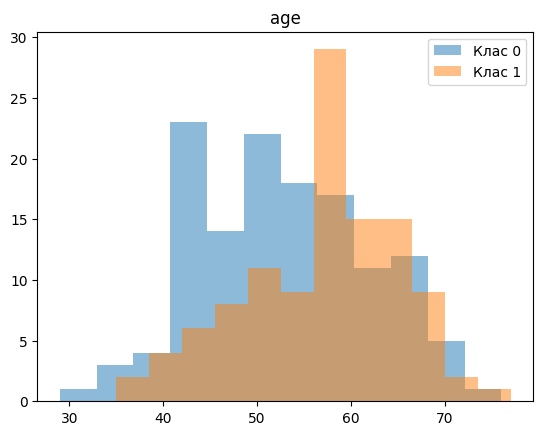

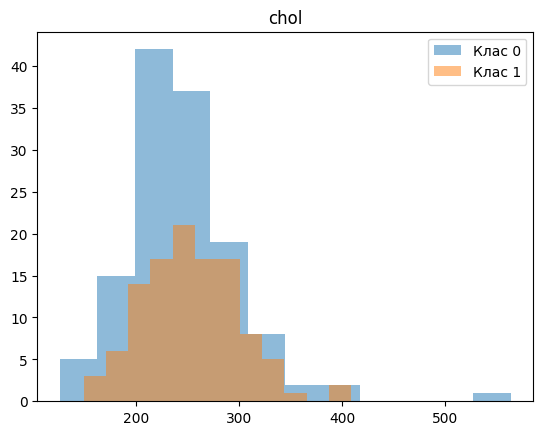

In [11]:
# k-NN: масштабування, k та відстані.
display(pd.DataFrame([evaluate('kNN без масштабу', pipe(KNeighborsClassifier(n_neighbors=5), False)),
                      evaluate('kNN з масштабом', pipe(KNeighborsClassifier(n_neighbors=5), True))]).round(3))
k_values = [3, 5, 7, 9, 11, 15]
k_table = pd.DataFrame([evaluate('kNN', pipe(KNeighborsClassifier(n_neighbors=k)), {'k':k}) | {'k':k}
                        for k in k_values])
display(k_table[['k', 'cv_f1', 'cv_f1_std']].round(3))
plt.plot(k_table.k, k_table.cv_f1, 'o-'); plt.xlabel('k'); plt.ylabel('CV F1'); plt.title('k-NN'); plt.show()
best_k = int(best_row(k_table).k)
distance_table = pd.DataFrame([evaluate('kNN', pipe(KNeighborsClassifier(n_neighbors=best_k, metric=m)),
                                       {'k':best_k, 'metric':m}) | {'metric':m} for m in ['euclidean', 'manhattan']])
display(distance_table[['metric', 'cv_f1', 'cv_f1_std', 'cv_auc']].round(3))
distance = best_row(distance_table).metric
knn_model = pipe(KNeighborsClassifier(n_neighbors=best_k, metric=distance))
print('Найкращий k-NN:', best_k, distance)

# GaussianNB: описові гістограми на train, без тестових даних.
for col in ['age', 'chol']:
    for value in [0, 1]:
        plt.hist(X_train.loc[y_train == value, col].dropna(), bins=12, alpha=.5, label=f'Клас {value}')
    plt.title(col); plt.legend(); plt.show()

In [12]:
# Ймовірнісні моделі і стабільність QDA.
prob_models = {'GaussianNB':pipe(GaussianNB()), 'LDA':pipe(LinearDiscriminantAnalysis())}
prob_rows = [evaluate(name, model) for name, model in prob_models.items()]
qda_rows = []
for reg in [0, .01, .1]:
    model = pipe(QuadraticDiscriminantAnalysis(reg_param=reg), drop='first')
    try:
        row = evaluate('QDA', model, {'reg_param':reg})
        row['reg_param'] = reg
        row['status'] = 'нестабільна' if row['critical_warning_count'] else 'стабільна'
    except (ValueError, np.linalg.LinAlgError) as exc:
        row = {'reg_param':reg, 'status':str(exc), 'cv_f1':np.nan,
               'critical_warning_count':-1}
    qda_rows.append(row)
qda_table = pd.DataFrame(qda_rows)
display(qda_table[['reg_param', 'status', 'cv_f1', 'warning_count', 'critical_warning_count']].round(3))
valid = qda_table.query('status == "стабільна"')
if not valid.empty:
    qda_reg = float(best_row(valid).reg_param)
    prob_models['QDA'] = pipe(QuadraticDiscriminantAnalysis(reg_param=qda_reg), drop='first')
    prob_rows.append(evaluate('QDA', prob_models['QDA'], {'reg_param':qda_reg}))
else:
    print('QDA нестабільна — пояснення зафіксовано; у фінальний рейтинг її не додаємо.')
prob_table = pd.DataFrame(prob_rows)
display(prob_table[['model', 'cv_f1', 'cv_f1_std', 'cv_auc', 'cv_recall']].round(3))

# Позавибіркові ймовірності (навчальні дані).
oof = pd.DataFrame({'class':y_train.iloc[:6].to_numpy()})
for name, model in prob_models.items():
    oof[name] = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba')[:6, 1]
display(oof.round(3))
best_prob = best_row(prob_table).model
print('Висновок ПР5: найкраща ймовірнісна модель:', best_prob,
      '. Масштабування, k і відстань впливають на k-NN.')

,reg_param,status,cv_f1,warning_count,critical_warning_count
0,0.00,нестабільна,0.634,7,5
1,0.01,стабільна,0.775,2,0
2,0.10,стабільна,0.787,2,0


,model,cv_f1,cv_f1_std,cv_auc,cv_recall
0,GaussianNB,0.749,0.021,0.877,0.846
1,LDA,0.813,0.026,0.899,0.766
2,QDA,0.787,0.038,0.868,0.765


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,class,GaussianNB,LDA,QDA
0,1,1.000,0.904,0.575
1,0,0.000,0.022,0.012
2,0,0.000,0.473,0.131
3,0,0.434,0.161,0.039
4,1,1.000,0.617,0.702
5,1,1.000,0.979,0.988


Висновок ПР5: найкраща ймовірнісна модель: LDA . Масштабування, k і відстань впливають на k-NN.


# Практична робота 6. Linear SVM, RBF SVM і GridSearchCV
Шукаємо параметри за тією ж CV; gamma задається тільки для RBF.

In [13]:
svm_search = GridSearchCV(pipe(SVC()), [
    {'classifier__kernel':['linear'], 'classifier__C':[.1, 1, 10]},
    {'classifier__kernel':['rbf'], 'classifier__C':[.1, 1, 10],
     'classifier__gamma':['scale', .01, .1]}
], cv=cv, scoring='f1', n_jobs=1)
svm_search.fit(X_train, y_train)
print('Найкращі SVM параметри:', svm_search.best_params_, 'CV F1:', round(svm_search.best_score_, 3))
svm_grid = pd.DataFrame(svm_search.cv_results_)
display(svm_grid[['params', 'mean_test_score', 'std_test_score', 'mean_fit_time']]
        .sort_values('mean_test_score', ascending=False).head(8).round(3))
svm_rows = []
svm_models = {}
for kernel in ['linear', 'rbf']:
    sub = svm_grid.loc[svm_grid.param_classifier__kernel == kernel]
    params = sub.sort_values(['mean_test_score', 'std_test_score'], ascending=[False, True]).iloc[0]['params']
    conf = {k.removeprefix('classifier__'):v for k,v in params.items()}
    svm_models[kernel] = pipe(SVC(**conf))
    svm_rows.append(evaluate('SVM '+kernel, svm_models[kernel], conf))
svm_table = pd.DataFrame(svm_rows)
display(svm_table[['model', 'cv_f1', 'cv_f1_std', 'cv_auc', 'seconds']].round(3))
best_svm = svm_models[best_row(svm_table).model.split()[-1]]
print('Висновок ПР6: більше C — слабша регуляризація; велике gamma може спричиняти перенавчання.')

Найкращі SVM параметри: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'} CV F1: 0.827


,params,mean_test_score,std_test_score,mean_fit_time
10,"{'classifier__C': 10, 'classifier__gamma': 0.0...",0.827,0.033,0.019
1,"{'classifier__C': 1, 'classifier__kernel': 'li...",0.803,0.031,0.029
2,"{'classifier__C': 10, 'classifier__kernel': 'l...",0.800,0.026,0.028
0,"{'classifier__C': 0.1, 'classifier__kernel': '...",0.796,0.054,0.033
7,"{'classifier__C': 1, 'classifier__gamma': 0.01...",0.795,0.029,0.018
8,"{'classifier__C': 1, 'classifier__gamma': 0.1,...",0.789,0.027,0.019
6,"{'classifier__C': 1, 'classifier__gamma': 'sca...",0.789,0.027,0.018
5,"{'classifier__C': 0.1, 'classifier__gamma': 0....",0.765,0.017,0.018


,model,cv_f1,cv_f1_std,cv_auc,seconds
0,SVM linear,0.803,0.031,0.898,0.018
1,SVM rbf,0.827,0.033,0.897,0.018


Висновок ПР6: більше C — слабша регуляризація; велике gamma може спричиняти перенавчання.


# Практична робота 7. Остаточне порівняння та тестування
Правило вибору до перегляду test: максимальний CV F1, потім CV Recall, потім менший CV F1 std.

,model,params,cv_f1,cv_f1_std,cv_auc,cv_recall,seconds
0,LogisticRegression,"{'C': 100.0, 'class_weight': None, 'dual': Fal...",0.836,0.013,0.897,0.802,0.040
1,SVM,"{'C': 10, 'break_ties': False, 'cache_size': 2...",0.827,0.033,0.897,0.783,0.030
2,kNN,"{'algorithm': 'auto', 'leaf_size': 30, 'metric...",0.818,0.030,0.877,0.792,0.023
3,LDA,"{'covariance_estimator': None, 'n_components':...",0.813,0.026,0.899,0.766,0.027
4,QDA,"{'priors': None, 'reg_param': 0.1, 'store_cova...",0.787,0.038,0.868,0.765,0.024
5,GaussianNB,"{'priors': None, 'var_smoothing': 1e-09}",0.749,0.021,0.877,0.846,0.023


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


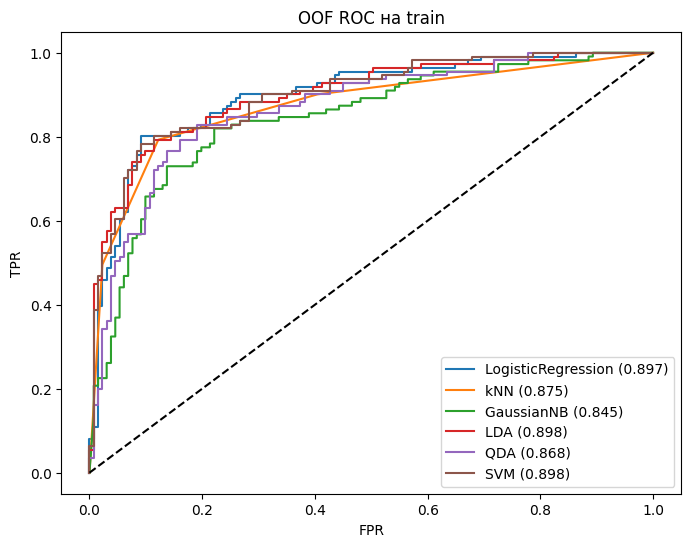

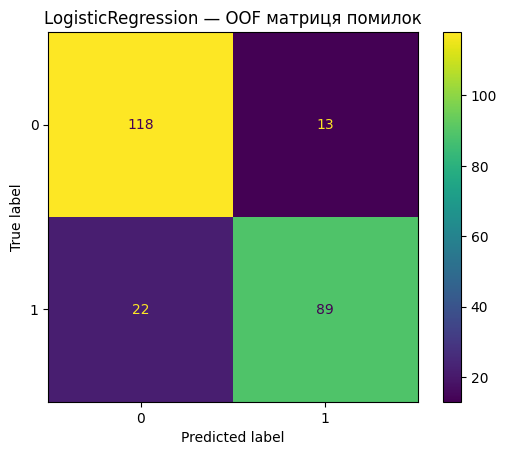

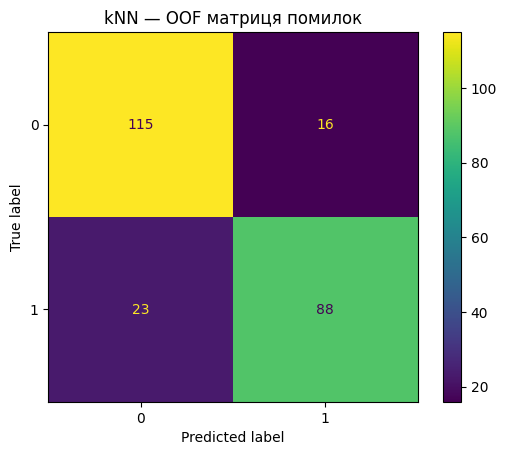

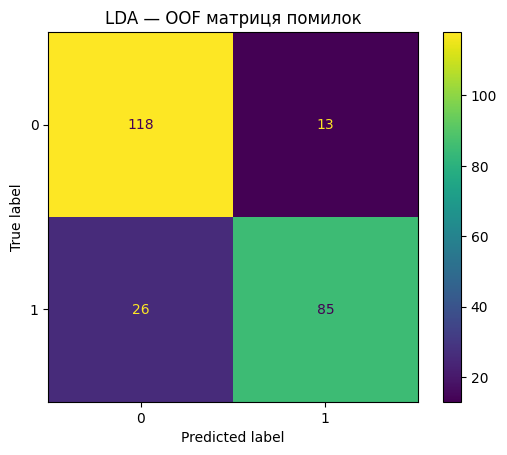

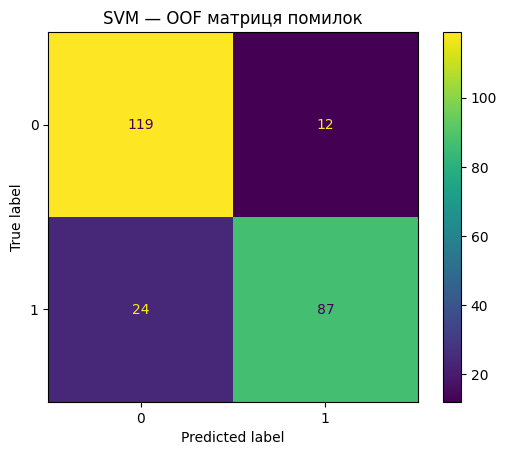

ФІКСАЦІЯ ДО TEST: {'model': 'LogisticRegression', 'params': "{'C': 100.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 2000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l1', 'random_state': 42, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}", 'cv_f1': 0.8363, 'criterion': 'max CV F1, then recall, then min std'}
Обрано за однаковою крос-валідацією, тестові дані не використовувалися.


In [14]:
candidates = {'LogisticRegression':log_model, 'kNN':knn_model,
              **prob_models, 'SVM':best_svm}
ranking = pd.DataFrame([evaluate(name, model, model.named_steps['classifier'].get_params())
                        for name, model in candidates.items()])
ranking = ranking.sort_values(['cv_f1', 'cv_recall', 'cv_f1_std', 'model'],
                              ascending=[False, False, True, True]).reset_index(drop=True)
display(ranking[['model', 'params', 'cv_f1', 'cv_f1_std', 'cv_auc', 'cv_recall', 'seconds']].round(3))
ranking.to_csv(ROOT / 'reports' / 'cv_model_comparison.csv', index=False)

# OOF ROC і матриці помилок — тільки навчальні дані.
plt.figure(figsize=(8, 6))
oof_preds = {}
for name, model in candidates.items():
    oof_preds[name] = cross_val_predict(model, X_train, y_train, cv=cv)
    method = 'decision_function' if name == 'SVM' else 'predict_proba'
    values = cross_val_predict(model, X_train, y_train, cv=cv, method=method)
    score = values if method == 'decision_function' else values[:, 1]
    fpr, tpr, _ = roc_curve(y_train, score)
    plt.plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_train, score):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.title('OOF ROC на train'); plt.xlabel('FPR'); plt.ylabel('TPR')
plt.legend(); plt.show()
for name in dict.fromkeys(['LogisticRegression', 'kNN', best_prob, 'SVM']):
    ConfusionMatrixDisplay.from_predictions(y_train, oof_preds[name], labels=[0,1])
    plt.title(name+' — OOF матриця помилок'); plt.show()

# Фіксуємо модель і параметри ДО тестування.
chosen = ranking.iloc[0]
chosen_name = chosen['model']
chosen_model = candidates[chosen_name]
selection = {'model':chosen_name, 'params':chosen['params'],
             'cv_f1':round(float(chosen.cv_f1), 4), 'criterion':'max CV F1, then recall, then min std'}
with open(ROOT/'reports'/'final_model_selection.json','w',encoding='utf-8') as f:
    json.dump(selection, f, ensure_ascii=False, indent=2)
print('ФІКСАЦІЯ ДО TEST:', selection)
print('Обрано за однаковою крос-валідацією, тестові дані не використовувалися.')

,model,accuracy,precision,recall,f1,roc_auc
0,LogisticRegression,0.869,0.833,0.893,0.862,0.958


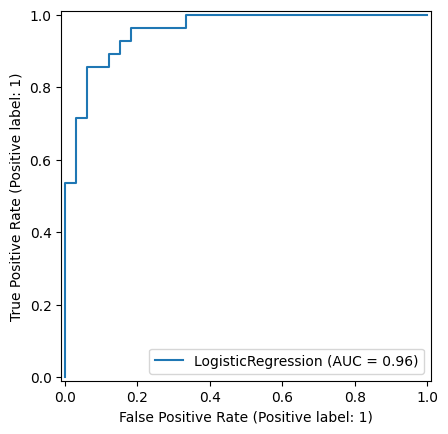

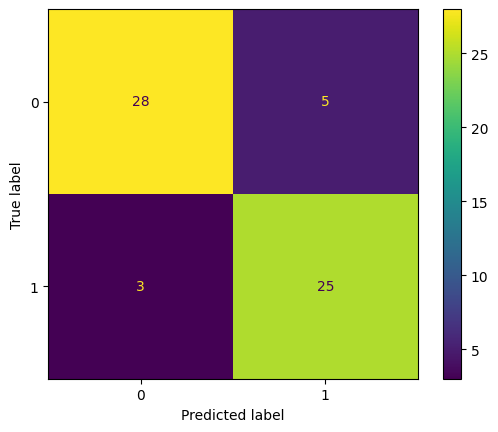

Помилок на test: 8


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,actual,predicted
271,66,1,4,160,228,0,2,138,0,2.3,1,0.0,6.0,0,1
196,69,1,1,160,234,1,2,131,0,0.1,2,1.0,3.0,0,1
33,59,1,4,135,234,0,0,161,0,0.5,2,0.0,7.0,0,1
292,44,1,4,120,169,0,0,144,1,2.8,3,0.0,6.0,1,0
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0,1


Фінальний Pipeline збережено й перевірено.


In [16]:
# Тестова вибірка використовується вперше, лише для обраного Pipeline.
assert (ROOT/'reports'/'final_model_selection.json').exists()
chosen_model.fit(X_train, y_train)
pred = chosen_model.predict(X_test)
score = (chosen_model.decision_function(X_test) if chosen_name == 'SVM'
         else chosen_model.predict_proba(X_test)[:, 1])
metrics = pd.DataFrame([dict(model=chosen_name, accuracy=accuracy_score(y_test, pred),
    precision=precision_score(y_test, pred, zero_division=0),
    recall=recall_score(y_test, pred), f1=f1_score(y_test, pred),
    roc_auc=roc_auc_score(y_test, score))])
display(metrics.round(3))
metrics.to_csv(ROOT/'reports'/'final_test_metrics.csv', index=False)
RocCurveDisplay.from_predictions(y_test, score, name=chosen_name); plt.show()
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0,1]); plt.show()
errors = X_test.copy()
errors['actual'], errors['predicted'] = y_test.values, pred
errors = errors.loc[errors.actual != errors.predicted]
print('Помилок на test:', len(errors)); display(errors.head())
joblib.dump(chosen_model, ROOT/'models'/'best_classifier.joblib')
reloaded = joblib.load(ROOT/'models'/'best_classifier.joblib')
assert np.array_equal(pred[:3], reloaded.predict(X_test.head(3)))
print('Фінальний Pipeline збережено й перевірено.')

In [17]:
# Короткий підсумок для README і звіту.
print('Найкраща модель:', chosen_name)
print('CV F1:', round(float(chosen.cv_f1), 3))
print('Test F1:', round(float(metrics.f1.iloc[0]), 3))
print('Test ROC AUC:', round(float(metrics.roc_auc.iloc[0]), 3))
print('Кількість тестових помилок:', len(errors))
print('Висновок: модель обрана тільки за CV на train; test застосовано один раз.')

Найкраща модель: LogisticRegression
CV F1: 0.836
Test F1: 0.862
Test ROC AUC: 0.958
Кількість тестових помилок: 8
Висновок: модель обрана тільки за CV на train; test застосовано один раз.


In [18]:
# README мініпроєкту: підсумок власного експерименту.
readme = f"""# Порівняння класичних моделей класифікації

**Студент:** Шаповалов Владислав, ІН-32/2
**Дисципліна:** Розпізнавання образів та класичне машинне навчання

## Дані та метод
Heart Disease: {len(data)} спостереження, {len(X.columns)} вхідних ознак.
Бінарна ціль `target` (позитивний клас 1). Фіксоване стратифіковане розбиття
80/20; 5-кратна StratifiedKFold лише на train.

Порівняно Logistic Regression (L1/L2), k-NN, GaussianNB, LDA, QDA та SVM.
Попередня обробка (імпутація, кодування, масштабування) виконується всередині Pipeline.

## Результати
Найкращий за CV F1 алгоритм: **{chosen_name}** (CV F1 = {chosen.cv_f1:.3f}).
Test: accuracy = {metrics.accuracy.iloc[0]:.3f}, precision = {metrics.precision.iloc[0]:.3f},
recall = {metrics.recall.iloc[0]:.3f}, F1 = {metrics.f1.iloc[0]:.3f},
ROC AUC = {metrics.roc_auc.iloc[0]:.3f}; помилок = {len(errors)}.
Фінальний Pipeline обрано до оцінювання test і після перегляду метрик не змінювали.
Результати є навчальними та не призначені для медичного використання.

[Відкрити Notebook](notebooks/PR04_Shapovalov_Vladyslav.ipynb)

У папці reports збережено таблиці CV-метрик та фінальних test-метрик,
у папці models — best_classifier.joblib.
"""
(ROOT / 'README.md').write_text(readme, encoding='utf-8')
print('README створено:', ROOT / 'README.md')

README створено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/README.md
